# Credit Risk — Exploratory Data Analysis

Phase 1 exploration of the synthetic credit risk dataset (`applicants`,
`loan_applications`, `payments` tables in `bank_db`).

Goal: understand the data before touching a model — check that the
distributions and relationships look plausible, and that the default
pattern I deliberately designed in `generate_data.py` actually shows up
in the data, not just in the generation code.

## 1. Setup — imports and connection

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg2

sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Pull data from Postgres

Two separate pulls:
- `df`: `applicants` joined to `loan_applications` — one row per loan
- `payments_df`: the full `payments` table, kept separate since it's
  one-to-many against `df` (a loan can have 0, 1, or many payments)

In [8]:
conn = psycopg2.connect(
    host="localhost",
    port=5432,
    dbname="bank_db",
    user="postgres",
    password="devpass",
)

df = pd.read_sql("""
    SELECT a.*, l.loan_id, l.loan_amount_requested, l.debt, l.defaulted, l.application_date
    FROM applicants a
    JOIN loan_applications l ON a.applicant_id = l.applicant_id
""", conn)

payments_df = pd.read_sql("SELECT * FROM payments", conn)

conn.close()

print(f"df shape: {df.shape}")
print(f"payments_df shape: {payments_df.shape}")
df.head()

df shape: (5021, 11)
payments_df shape: (21, 4)


/var/folders/mb/9y6pxy613_x_ync4yzkhl_1m0000gn/T/ipykernel_45221/2179682557.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("""
/var/folders/mb/9y6pxy613_x_ync4yzkhl_1m0000gn/T/ipykernel_45221/2179682557.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  payments_df = pd.read_sql("SELECT * FROM payments", conn)


,applicant_id,age,income,employment_length_months,credit_history_months,existing_credit_lines,loan_id,loan_amount_requested,debt,defaulted,application_date
0,1,56,34246.87,145.0,272,2,1,2515.04,102740.61,False,2026-09-25
1,2,25,33784.38,11.0,54,1,2,16640.28,9273.38,False,2026-09-25
2,3,36,96083.69,17.0,98,2,3,58631.40,86875.62,False,2026-09-25
3,4,40,47703.73,30.0,101,0,4,12799.49,39427.18,False,2026-09-25
4,5,25,20939.56,40.0,28,1,5,4375.51,2070.60,False,2026-09-25


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5021 entries, 0 to 5020
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   applicant_id              5021 non-null   int64  
 1   age                       5021 non-null   int64  
 2   income                    4942 non-null   float64
 3   employment_length_months  4948 non-null   float64
 4   credit_history_months     5021 non-null   int64  
 5   existing_credit_lines     5021 non-null   int64  
 6   loan_id                   5021 non-null   int64  
 7   loan_amount_requested     5021 non-null   float64
 8   debt                      5021 non-null   float64
 9   defaulted                 5021 non-null   bool   
 10  application_date          5021 non-null   object 
dtypes: bool(1), float64(4), int64(5), object(1)
memory usage: 397.3+ KB


In [10]:
df.describe(include="all")

,applicant_id,age,income,employment_length_months,credit_history_months,existing_credit_lines,loan_id,loan_amount_requested,debt,defaulted,application_date
count,5021.000000,5021.000000,4942.000000,4948.000000,5021.000000,5021.000000,5021.000000,5021.000000,5021.000000,5021,5021
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,2026-09-25
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4486,5021
mean,2511.000000,37.822147,38961.362596,58.136823,127.800637,1.691097,2511.000000,14496.354772,20192.743318,NaN,NaN
std,1449.582181,10.751245,19722.556033,70.571006,83.363806,1.334188,1449.582181,10057.597104,21295.838039,NaN,NaN
min,1.000000,18.000000,8000.000000,0.000000,0.000000,0.000000,1.000000,500.000000,609.560000,NaN,NaN
25%,1256.000000,30.000000,24795.840000,11.000000,66.000000,1.000000,1256.000000,7246.670000,7592.730000,NaN,NaN
50%,2511.000000,38.000000,35132.735000,34.000000,118.000000,2.000000,2511.000000,12250.480000,13611.430000,NaN,NaN
75%,3766.000000,45.000000,48771.070000,78.000000,178.000000,2.000000,3766.000000,19105.800000,24810.790000,NaN,NaN


## 3. Payments — compute per-loan repayment activity

`payments_df` is one row per payment event. To be useful joined back
onto `df` (one row per loan), aggregate it up to loan level first:
total amount repaid so far, and number of payments made.

In [11]:
payment_summary = (
    payments_df
    .groupby("loan_id")
    .agg(
        total_repaid=("amount", "sum"),
        num_payments=("amount", "count"),
        avg_payment=("amount", "mean"),
        last_payment_date=("payment_date", "max"),
    )
    .reset_index()
)

print(f"Loans with at least one payment: {len(payment_summary)} / {df['loan_id'].nunique()}")
payment_summary.head()

Loans with at least one payment: 21 / 5021


,loan_id,total_repaid,num_payments,avg_payment,last_payment_date
0,769,370.89,1,370.89,2026-09-25
1,810,772.49,1,772.49,2026-09-25
2,834,2878.03,1,2878.03,2026-09-25
3,857,1212.42,1,1212.42,2026-09-25
4,1013,445.23,1,445.23,2026-09-25


In [12]:
# Left join onto df — loans with zero payments should show up as
# NaN/0 after this, not silently disappear
df = df.merge(payment_summary, on="loan_id", how="left")

df["num_payments"] = df["num_payments"].fillna(0).astype(int)
df["total_repaid"] = df["total_repaid"].fillna(0)

df[["loan_id", "loan_amount_requested", "total_repaid", "num_payments", "defaulted"]].head(10)

,loan_id,loan_amount_requested,total_repaid,num_payments,defaulted
0,1,2515.04,0.0,0,False
1,2,16640.28,0.0,0,False
2,3,58631.40,0.0,0,False
3,4,12799.49,0.0,0,False
4,5,4375.51,0.0,0,False
5,6,26365.99,0.0,0,False
6,7,5054.48,0.0,0,False
7,8,18423.06,0.0,0,False
8,9,11058.54,0.0,0,False
9,10,6292.79,0.0,0,False


## 4. Distribution of `income` and `debt`

Plotting both the raw distribution and a log-scale version — income and
debt are typically right-skewed (a long tail of high earners/high debt),
so a log scale often reveals the shape more clearly than a linear one.

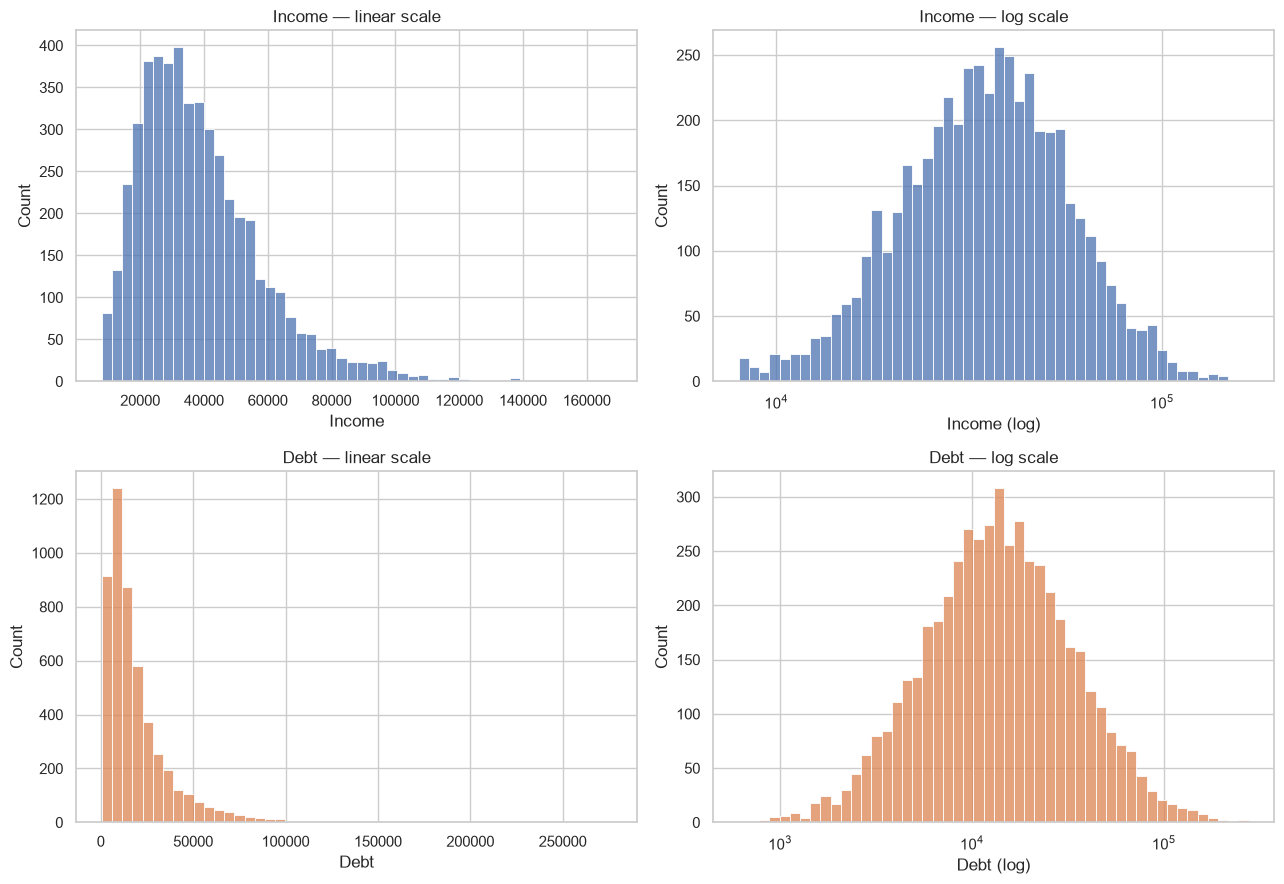

              income           debt
count    4942.000000    5021.000000
mean    38961.362596   20192.743318
std     19722.556033   21295.838039
min      8000.000000     609.560000
25%     24795.840000    7592.730000
50%     35132.735000   13611.430000
75%     48771.070000   24810.790000
max    167765.060000  276435.510000


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df["income"].dropna(), bins=50, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Income — linear scale")
axes[0, 0].set_xlabel("Income")

sns.histplot(df["income"].dropna(), bins=50, ax=axes[0, 1], color="#4C72B0", log_scale=True)
axes[0, 1].set_title("Income — log scale")
axes[0, 1].set_xlabel("Income (log)")

sns.histplot(df["debt"].dropna(), bins=50, ax=axes[1, 0], color="#DD8452")
axes[1, 0].set_title("Debt — linear scale")
axes[1, 0].set_xlabel("Debt")

sns.histplot(df["debt"].dropna(), bins=50, ax=axes[1, 1], color="#DD8452", log_scale=True)
axes[1, 1].set_title("Debt — log scale")
axes[1, 1].set_xlabel("Debt (log)")

plt.tight_layout()
plt.show()

print(df[["income", "debt"]].describe())

## 5. Debt-to-income ratio

Not a raw column — computed here purely for exploration, since it's the
single feature `generate_loan_application()` weighted most heavily in
the risk score.

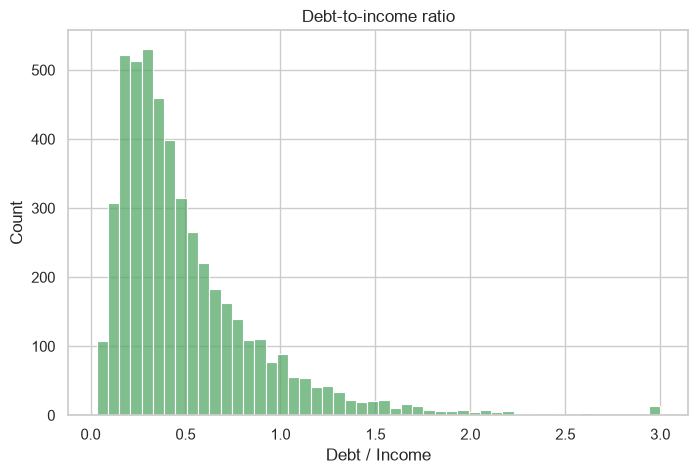

count    4942.000000
mean        0.508203
std         0.396643
min         0.031933
25%         0.246280
50%         0.392357
75%         0.649327
max         3.000000
Name: debt_to_income, dtype: float64

In [14]:
df["debt_to_income"] = df["debt"] / df["income"]

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["debt_to_income"].dropna(), bins=50, ax=ax, color="#55A868")
ax.set_title("Debt-to-income ratio")
ax.set_xlabel("Debt / Income")
plt.show()

df["debt_to_income"].describe()

## 6. Default rate by `credit_history_months` bucket

This is the key check against your own design: `generate_loan_application()`
weighted `credit_history_months` *negatively* in the risk score (longer
history → lower default probability). Bucketing into ranges and plotting
default rate per bucket should show a visible downward trend if that
design choice actually made it into the data correctly.

                       default_rate  n_loans
credit_history_bucket                       
0-2yr                      0.435950      484
2-5yr                      0.239567      647
5-10yr                     0.091349     1445
10-16.5yr                  0.023380     1497
16.5yr+                    0.002110      948


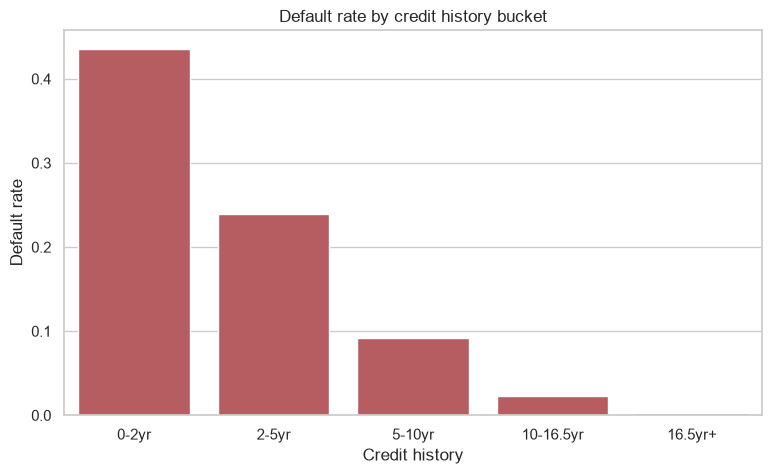

In [15]:
# Bucket credit_history_months into readable ranges
bins = [0, 24, 60, 120, 200, df["credit_history_months"].max() + 1]
labels = ["0-2yr", "2-5yr", "5-10yr", "10-16.5yr", "16.5yr+"]
df["credit_history_bucket"] = pd.cut(df["credit_history_months"], bins=bins, labels=labels, include_lowest=True)

# Only resolved loans have a real defaulted value — unresolved (NULL)
# loans should be excluded from a default-rate calculation, since they
# haven't had a chance to default yet.
resolved = df[df["defaulted"].notna()]

default_by_bucket = resolved.groupby("credit_history_bucket", observed=True)["defaulted"].agg(["mean", "count"])
default_by_bucket.columns = ["default_rate", "n_loans"]
print(default_by_bucket)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=default_by_bucket.index, y=default_by_bucket["default_rate"], ax=ax, color="#C44E52")
ax.set_title("Default rate by credit history bucket")
ax.set_ylabel("Default rate")
ax.set_xlabel("Credit history")
plt.show()

## 7. Default rate by `existing_credit_lines`

Same check, for the other categorical-ish feature in the risk score —
this one was weighted *positively* (more lines → higher default risk),
so the expected trend direction is the opposite of Section 6.

                       default_rate  n_loans
existing_credit_lines                       
0                          0.113131      990
1                          0.112592     1501
2                          0.110176     1307
3                          0.090663      739
4                          0.098765      324
5                          0.062500      112
6                          0.055556       36
7                          0.200000       10
8                          0.000000        1
9                          0.000000        1


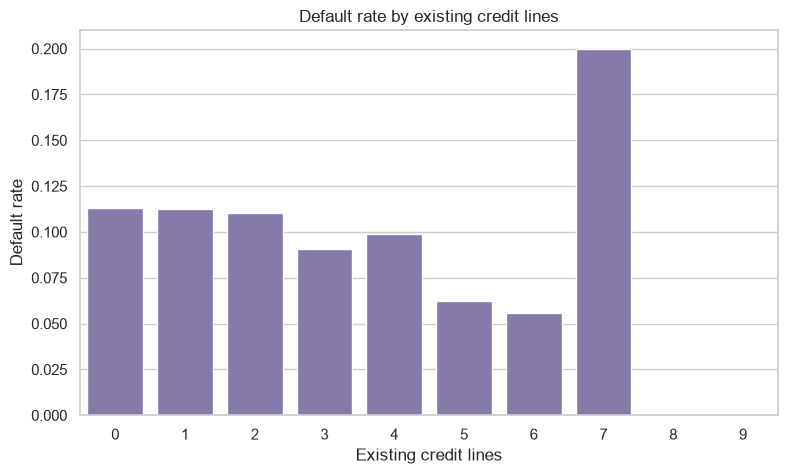

In [16]:
default_by_lines = resolved.groupby("existing_credit_lines")["defaulted"].agg(["mean", "count"])
default_by_lines.columns = ["default_rate", "n_loans"]
print(default_by_lines)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=default_by_lines.index, y=default_by_lines["default_rate"], ax=ax, color="#8172B2")
ax.set_title("Default rate by existing credit lines")
ax.set_ylabel("Default rate")
ax.set_xlabel("Existing credit lines")
plt.show()

## 8. Overall class balance of `defaulted`

A sanity check against the 5-15% target range from the generation step,
computed directly from what's actually in the database right now (which
may have shifted slightly if `simulate_activity.py` has been running).

Counts:
defaulted
False    4486
True      535
Name: count, dtype: int64

Proportions:
defaulted
False    0.893448
True     0.106552
Name: proportion, dtype: float64


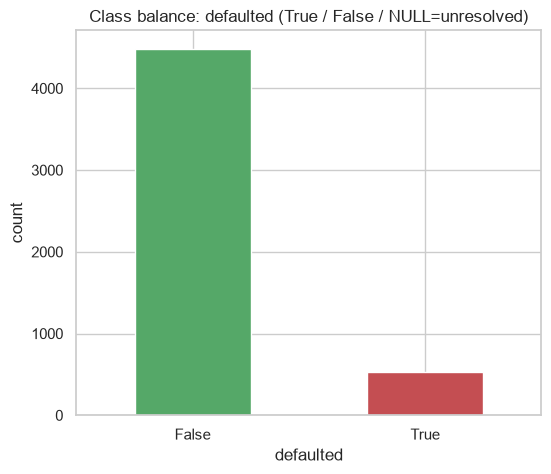

In [17]:
defaulted_counts = df["defaulted"].value_counts(dropna=False)
defaulted_pct = df["defaulted"].value_counts(normalize=True, dropna=False)

print("Counts:")
print(defaulted_counts)
print("\nProportions:")
print(defaulted_pct)

fig, ax = plt.subplots(figsize=(6, 5))
defaulted_counts.plot(kind="bar", ax=ax, color=["#55A868", "#C44E52", "#8C8C8C"])
ax.set_title("Class balance: defaulted (True / False / NULL=unresolved)")
ax.set_xlabel("defaulted")
ax.set_ylabel("count")
plt.xticks(rotation=0)
plt.show()

## 9. Correlation between key features and `defaulted`

Restricted to resolved loans only (an unresolved/NULL outcome can't be
correlated against anything meaningfully). `defaulted` is cast to int
(0/1) so it can be included in a numeric correlation matrix.

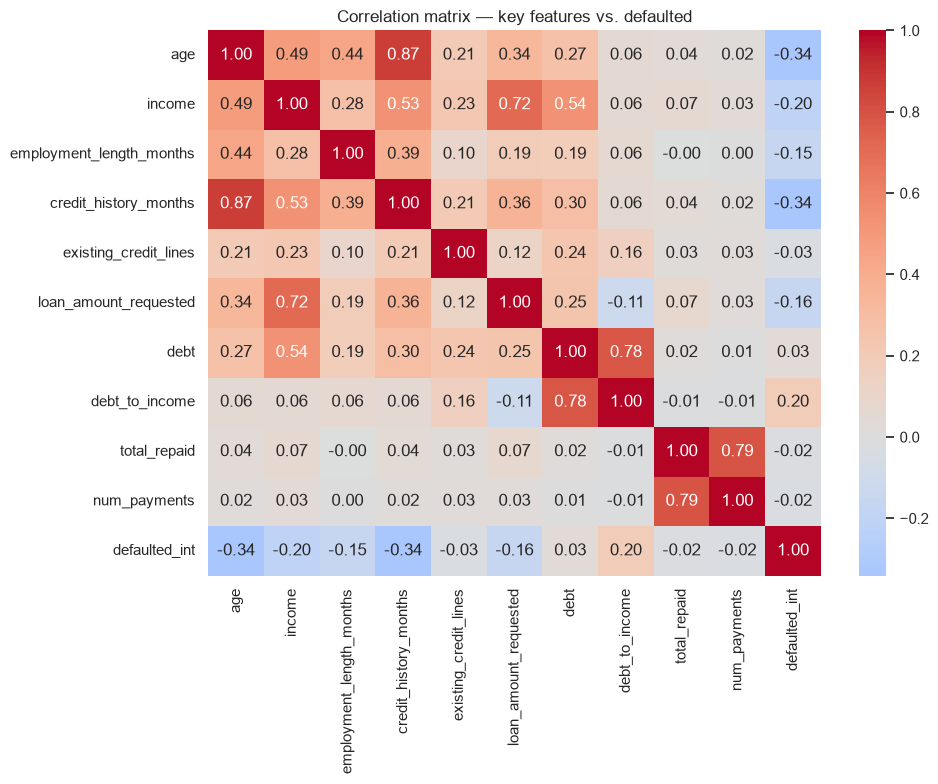

defaulted_int               1.000000
debt_to_income              0.198114
debt                        0.033508
total_repaid               -0.017758
num_payments               -0.022381
existing_credit_lines      -0.027937
employment_length_months   -0.153811
loan_amount_requested      -0.161851
income                     -0.200792
credit_history_months      -0.340114
age                        -0.341408
Name: defaulted_int, dtype: float64


In [18]:
corr_df = resolved.copy()
corr_df["defaulted_int"] = corr_df["defaulted"].astype(int)

features = [
    "age", "income", "employment_length_months", "credit_history_months",
    "existing_credit_lines", "loan_amount_requested", "debt",
    "debt_to_income", "total_repaid", "num_payments", "defaulted_int",
]

corr_matrix = corr_df[features].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix — key features vs. defaulted")
plt.tight_layout()
plt.show()

print(corr_matrix["defaulted_int"].sort_values(ascending=False))

## 10. Quick data quality glance

A lighter, visual companion to the full checks in
`shared/data_validation.py` — run that file separately for the complete
report. Here, just a couple of quick visual sanity checks worth seeing
directly in the notebook.

In [19]:
print("Missing values:")
print(df[["age", "income", "employment_length_months", "credit_history_months",
           "existing_credit_lines", "debt", "loan_amount_requested"]].isnull().sum())

print("\nDuplicate loan_id:", df["loan_id"].duplicated().sum())
print("Negative debt rows:", (df["debt"] < 0).sum())
print("Ages outside [18, 100]:", ((df["age"] < 18) | (df["age"] > 100)).sum())

Missing values:
age                          0
income                      79
employment_length_months    73
credit_history_months        0
existing_credit_lines        0
debt                         0
loan_amount_requested        0
dtype: int64

Duplicate loan_id: 0
Negative debt rows: 0
Ages outside [18, 100]: 0
